In [1]:
# Cell 1 - run information (required)
import os, subprocess, sys
BUNDLE = "/content/p2_bundle"
if os.path.isdir("/content"):                      # Colab: everything comes from p2_bundle.zip on Drive
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(BUNDLE):
        subprocess.run(["unzip", "-q", "/content/drive/MyDrive/genai_lab2/p2_bundle.zip", "-d", "/content"],
                       check=True)
    os.chdir(f"{BUNDLE}/data266-lab2-team32")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'commit': '03a89a9', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [12]:
!pip install -q torchao>=0.16.0

In [11]:
!pip uninstall -y -q torchao

# Part 2 - Fine-tuning Stable Diffusion 1.5 on Naruto images

DATA 266 Lab 2, Pair_Programming_Team_32. Runs on one Colab T4. Code is in `part2_diffusion/src/`,
settings in `part2_diffusion/configs/config.yaml`.

Everything (packages, dataset, SD 1.5, CLIP, metric weights) comes from `p2_bundle.zip` in Google
Drive; nothing is downloaded. Results go to `MyDrive/data266_p2`.

Set `TEST_RUN = True` first: 10 training steps and 3 prompts, about 15 minutes, to check that
everything works. Its files go to `MyDrive/data266_p2_test`. Then set it back to `False`.

In [2]:
TEST_RUN = False

if os.path.isdir("/content"):
    # packages, dataset, models and metric weights all come from the bundle: no downloads
    !pip install -q --no-index --no-deps {BUNDLE}/wheels/*.whl
    results = "/content/drive/MyDrive/genai_lab2/data266_p2" + ("_test" if TEST_RUN else "")
    os.environ.update(HF_HUB_OFFLINE="1", TORCH_HOME=f"{BUNDLE}/torch",
                      P2_RAW=f"{BUNDLE}/raw/data", P2_MODELS=f"{BUNDLE}/models",
                      P2_DATA="/content/data", P2_RESULTS=results, P2_BIG=f"{results}/big")

from importlib.metadata import version
for pkg in ["torch", "diffusers", "transformers", "peft", "datasets", "torchmetrics", "lpips"]:
    print(f"{pkg}=={version(pkg)}")

torch==2.14.1+cu130
diffusers==0.42.1
transformers==5.22.1
peft==0.21.2
datasets==4.8.5
torchmetrics==1.9.0
lpips==0.1.4


In [3]:
# Fix missing bundle files (run once after restart)
!wget -q -O /content/p2_bundle/models/stable-diffusion-v1-5/model_index.json \
  "https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/raw/main/model_index.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/pytorch_model.bin \
  "https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/pytorch_model.bin"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/config.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/preprocessor_config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/preprocessor_config.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/vocab.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/vocab.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/tokenizer_config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/tokenizer_config.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/special_tokens_map.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/special_tokens_map.json"
print("Done - missing files downloaded")

Done - missing files downloaded


## 2.1 Data preparation
Remove corrupted images (cannot be decoded), exact duplicates (same MD5) and near duplicates
(dHash distance of 4 bits or less); split 90/10 with seed 266; resize to 512x512.

Generating train split: 0 examples [00:00, ? examples/s]

loaded 1221 images
removed 0 {}
smallest dHash distance between kept images: 5
{
  "dataset": "lambdalabs/naruto-blip-captions",
  "rows_loaded": 1221,
  "removed": 0,
  "removed_by_reason": {},
  "kept": 1221,
  "train": 1099,
  "test": 122,
  "seed": 266,
  "closest_kept_dhash_distance": 5,
  "original_sizes_top5": {
    "1080x1080": 468,
    "1076x1076": 135,
    "1620x1620": 33,
    "1050x1050": 30,
    "540x540": 23
  },
  "caption_words_mean": 8.9,
  "top_caption_words": {
    "man": 692,
    "hair": 464,
    "white": 192,
    "shirt": 192,
    "eyes": 181,
    "long": 181,
    "black": 180,
    "woman": 175,
    "his": 163,
    "green": 142,
    "blue": 137,
    "hat": 126,
    "red": 115,
    "brown": 95,
    "sword": 86
  }
}


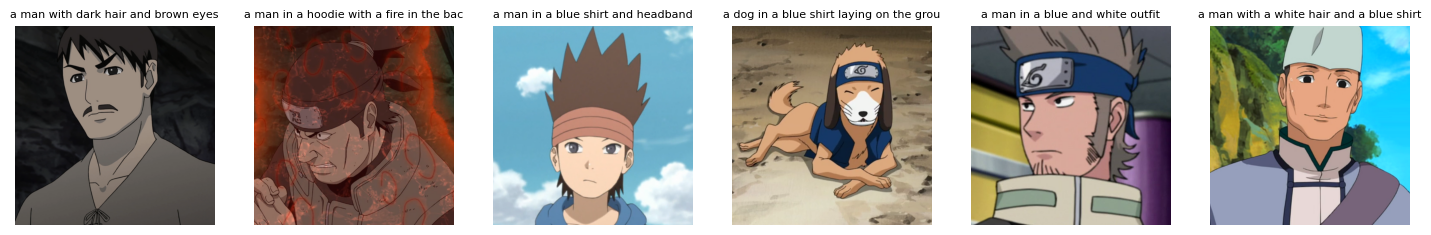

In [4]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from part2_diffusion.src import common, data

summary = data.prepare()
print(json.dumps(summary, indent=2))

train_rows = [json.loads(line) for line in open(common.DATA / "train" / "metadata.jsonl")][:6]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, row in zip(axes, train_rows):
    ax.imshow(Image.open(common.DATA / "train" / row["file_name"]))
    ax.set_title(row["text"][:40], fontsize=8)
    ax.axis("off")
plt.show()

In [5]:
prompts = common.load_prompts()
if TEST_RUN:   # one prompt per category
    prompts = [next(p for p in prompts if p["category"] == c)
               for c in ("in_domain", "out_of_domain", "compositional")]
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(prompts)

,prompt_id,category,prompt,source
0,ID01,in_domain,a dog and a man sitting on the ground,test-set caption
1,ID02,in_domain,a dog with a banda around its neck,test-set caption
2,ID03,in_domain,a man in a black hoodie with a sword,test-set caption
3,ID04,in_domain,a man in a green jacket and hat,test-set caption
4,ID05,in_domain,a man in a suit with a red dot on his face,test-set caption
5,ID06,in_domain,a man in the woods with a sword,test-set caption
6,ID07,in_domain,a man with a big smile on his face,test-set caption
7,ID08,in_domain,a man with black hair and blue eyes pointing at the camera,test-set caption
8,ID09,in_domain,a spider hanging from the ceiling of a room,test-set caption
9,ID10,in_domain,a woman with long brown hair and blue eyes,test-set caption


## 2.2 Fine-tuning
Two runs with the same data and step budget: LoRA rank 4 and LoRA rank 32. A run that has already
finished (weights on Drive) is not trained again.

In [6]:
from part2_diffusion.src import train
steps = 10 if TEST_RUN else None
stats = {run: train.train(run, max_steps=steps) for run in common.RUNS}

W1115 03:39:51.815000 4182 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 03:39:51.877000 4182 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


run1_lora_r4 already trained
run2_lora_r32 already trained


,rank,trainable_params,learning_rate,steps,batch_size,peak_gpu_memory_gb,training_minutes,gpu_hours,gpu
run1_lora_r4,4,797184,0.0001,1500,4,3.54,42.3,0.705,Tesla T4
run2_lora_r32,32,6377472,0.0001,1500,4,3.6,42.9,0.716,Tesla T4


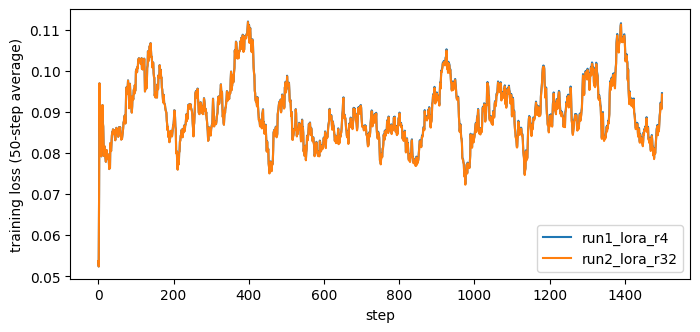

In [7]:
cols = ["rank", "trainable_params", "learning_rate", "steps", "batch_size",
        "peak_gpu_memory_gb", "training_minutes", "gpu_hours", "gpu"]
display(pd.DataFrame(stats).T[cols])

plt.figure(figsize=(8, 3.5))
for run, s in stats.items():
    smooth = pd.Series(s["losses"]).rolling(50, min_periods=1).mean()
    plt.plot(smooth, label=run, linewidth=1.5)
plt.xlabel("step"); plt.ylabel("training loss (50-step average)"); plt.legend()
plt.savefig(common.OUTPUTS / "loss_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 2.3 Image generation
Every prompt with seeds 0 and 1 for the base model and both runs, all with the same sampler
(DPM-Solver++, 30 steps, guidance 7.5). The pipeline's safety checker is on.

In [8]:
!wget -q -O /content/p2_bundle/models/stable-diffusion-v1-5/model_index.json \
  "https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/raw/main/model_index.json"

In [9]:
from part2_diffusion.src import generate
gens = generate.generate(prompts)
print(len(gens), "images,", gens["nsfw_flagged"].sum(), "flagged by the NSFW filter")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

base done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


run1_lora_r4 done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A blac

run2_lora_r32 done
120 images, 8 flagged by the NSFW filter


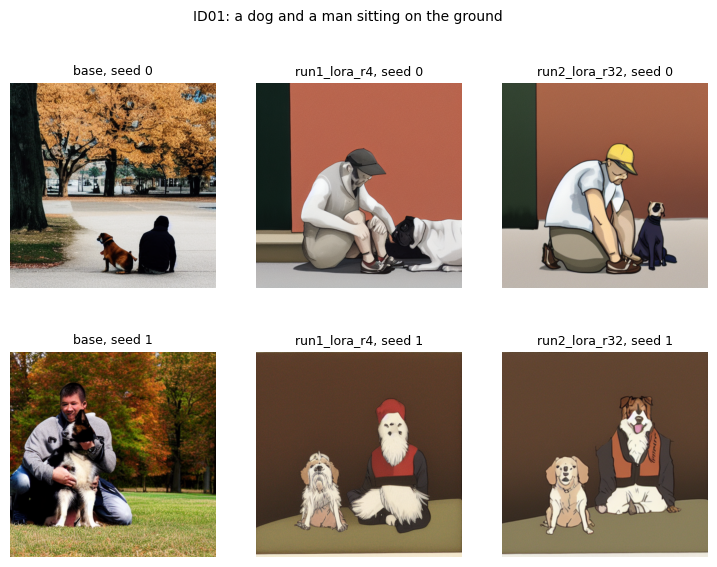

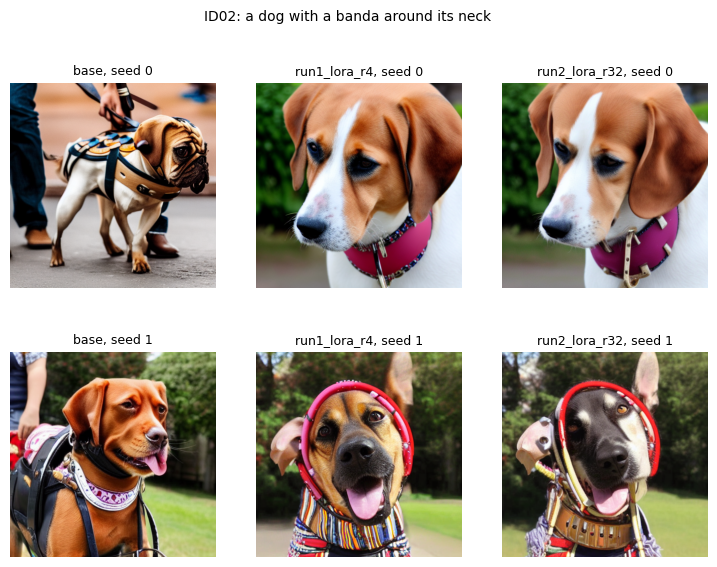

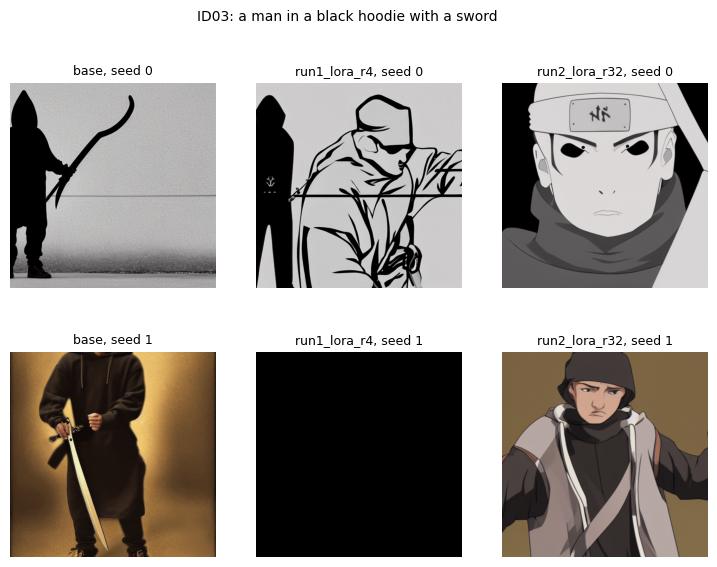

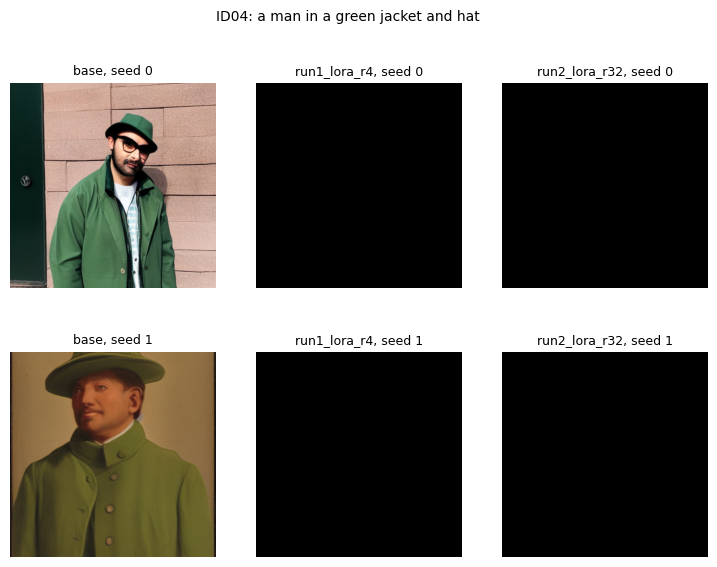

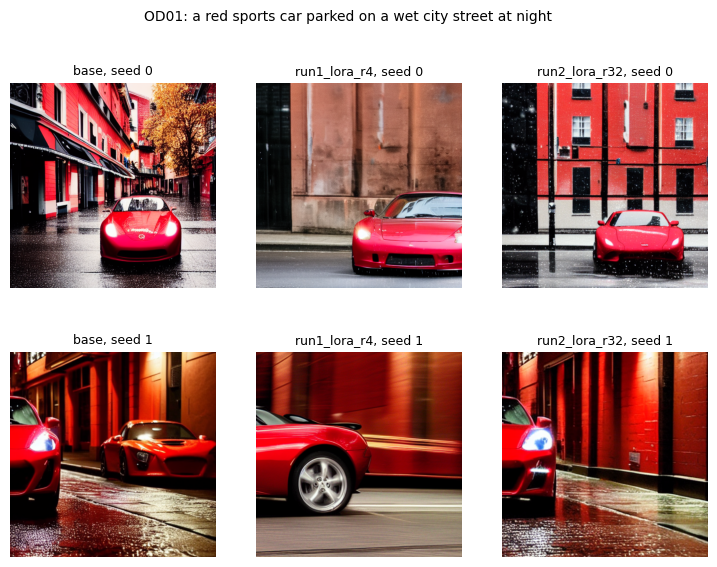

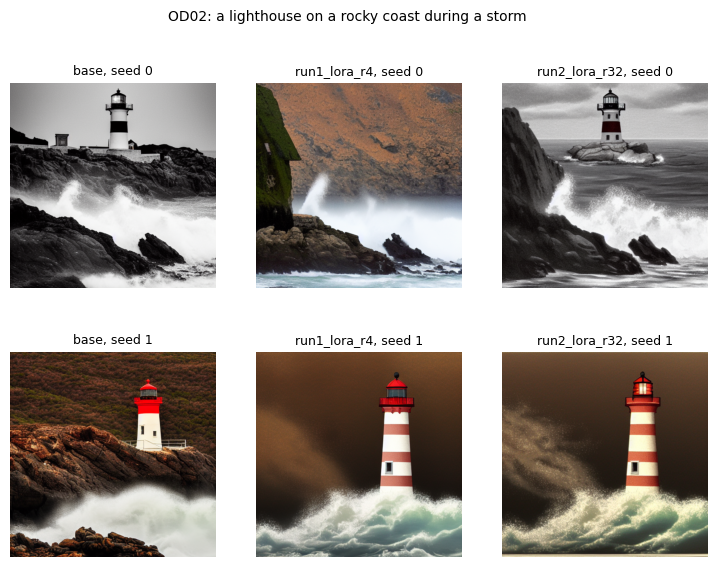

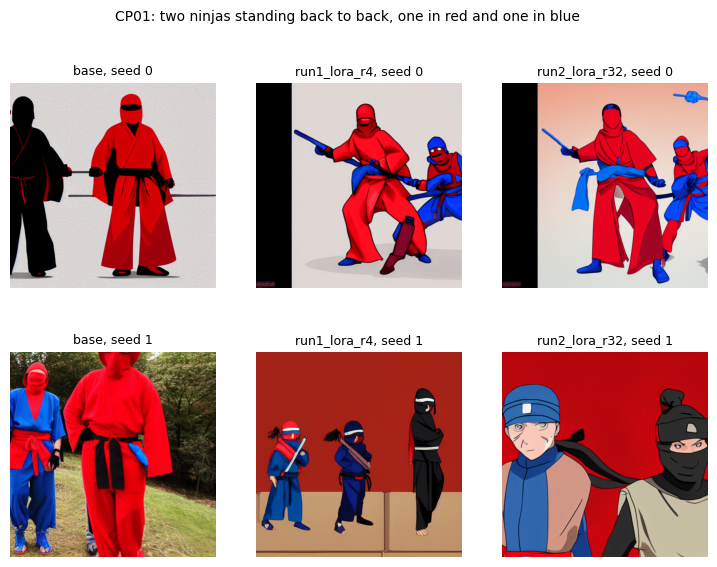

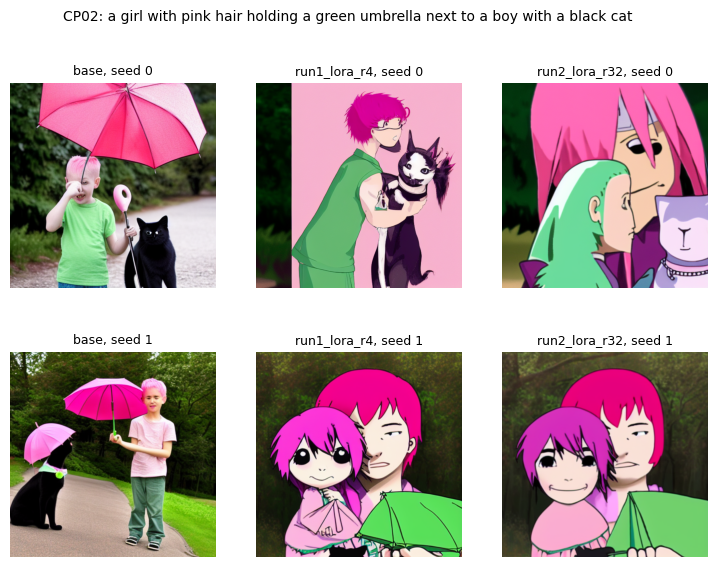

In [11]:
grid_ids = ["ID01", "ID02", "ID03", "ID04", "OD01", "OD02", "CP01", "CP02"]
(common.OUTPUTS / "grids").mkdir(parents=True, exist_ok=True)
for p in prompts:
    if p["prompt_id"] not in grid_ids:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(9, 6.4))
    for col, model in enumerate(common.MODELS):
        for row, seed in enumerate((0, 1)):
            axes[row, col].imshow(Image.open(common.image_path(model, p["prompt_id"], seed)))
            axes[row, col].set_title(f"{model}, seed {seed}", fontsize=9)
            axes[row, col].axis("off")
    fig.suptitle(f"{p['prompt_id']}: {p['prompt']}", fontsize=10)
    fig.savefig(common.OUTPUTS / "grids" / f"{p['prompt_id']}.jpg", dpi=80, bbox_inches="tight")
    plt.show()

## 2.4 Evaluation
Primary: KID (in-domain generations vs test images; noisy with only 20 images) and CLIP score.
Secondary: LPIPS between the two seeds of each prompt (diversity).

In [12]:
!rm -f /content/p2_bundle/models/clip-vit-base-patch32/model.safetensors
!rm -f /content/p2_bundle/models/clip-vit-base-patch32/pytorch_model.bin
!wget -O /content/p2_bundle/models/clip-vit-base-patch32/pytorch_model.bin \
  "https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/pytorch_model.bin"
!ls -lh /content/p2_bundle/models/clip-vit-base-patch32/

--2026-11-15 03:52:41--  https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/pytorch_model.bin
Resolving huggingface.co (huggingface.co)... 99.86.101.39, 99.86.101.56, 99.86.101.64, ...
Connecting to huggingface.co (huggingface.co)|99.86.101.39|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdc136468d709f17ea62/b9309dbadde00679b71e6cfd0d387b79e0b29d222133240986eaf9b4e3cd9e62?user_id=public&xip=rZeyg9QqaIo&response-content-type=application%2Foctet-stream&X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27pytorch_model.bin%3B+filename%3D%22pytorch_model.bin%22%3B&Expires=1794718361&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTdlYTYyL2I5MzA5ZGJhZGRlMDA2NzliNzFlNmNmZDBkMzg3Yjc5ZTBiMjlkMjIyMTMzMjQwOTg2ZWFmOWI0ZTNjZDllNjJcXD91c2VyX2lkPXB1YmxpYyZ4aXA9clpleWc5UXFhSW8mcmVzcG9uc2UtY29udGVudC10eXBlPSomWC

In [13]:
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/config.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/preprocessor_config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/preprocessor_config.json"
!ls /content/p2_bundle/models/clip-vit-base-patch32/

config.json  preprocessor_config.json  special_tokens_map.json	vocab.json
merges.txt   pytorch_model.bin	       tokenizer_config.json


In [14]:
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/vocab.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/vocab.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/tokenizer_config.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/tokenizer_config.json"
!wget -q -O /content/p2_bundle/models/clip-vit-base-patch32/special_tokens_map.json \
  "https://huggingface.co/openai/clip-vit-base-patch32/raw/main/special_tokens_map.json"

In [15]:
from part2_diffusion.src import evaluate
metrics, clip, clip_df = evaluate.evaluate(prompts)
display(metrics.round(4))
display(clip_df.groupby(["model", "category"])["clip_score"].mean().unstack().round(2))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


,kid_mean,kid_std,clip_score,clip_in_domain,lpips_between_seeds
base,0.1243,0.0181,31.8782,30.4415,0.8061
run1_lora_r4,0.0532,0.0247,29.8986,28.3327,0.7622
run2_lora_r32,0.0761,0.0478,29.3289,27.3170,0.7222


category,compositional,in_domain,out_of_domain
model,,,
base,34.91,30.44,31.72
run1_lora_r4,32.45,28.33,30.48
run2_lora_r32,30.79,27.32,31.89


In [17]:
# Final run: lower KID. Change this if the grids and the human vote point the other way.
FINAL_RUN = metrics.loc[common.RUNS, "kid_mean"].idxmin()
print("final run:", FINAL_RUN)

final run: run1_lora_r4


### Memorization check
For 10 in-domain images of the final run (seed 0), the most similar training image by CLIP
image similarity. The 3 closest pairs are shown.

,prompt_id,closest_train_image,train_caption,similarity
7,ID08,00252.png,a man with blonde hair and a white shirt,0.8975
9,ID10,01106.png,a girl with long brown hair and blue eyes,0.8015
6,ID07,01076.png,a man with a cigarette in his mouth,0.7708
4,ID05,01028.png,a man with a beard and a mustache,0.7568
2,ID03,00483.png,a man in a black robe with a hood over his head,0.7020
5,ID06,00419.png,a man in green pants and a white shirt,0.6972
3,ID04,00170.png,a white and black pokemon with a black background,0.6865
0,ID01,00696.png,a cat and a mouse in a room,0.6698
8,ID09,00210.png,a robot with a large green and orange body,0.6582
1,ID02,00987.png,a dog with its tongue out in the grass,0.6480


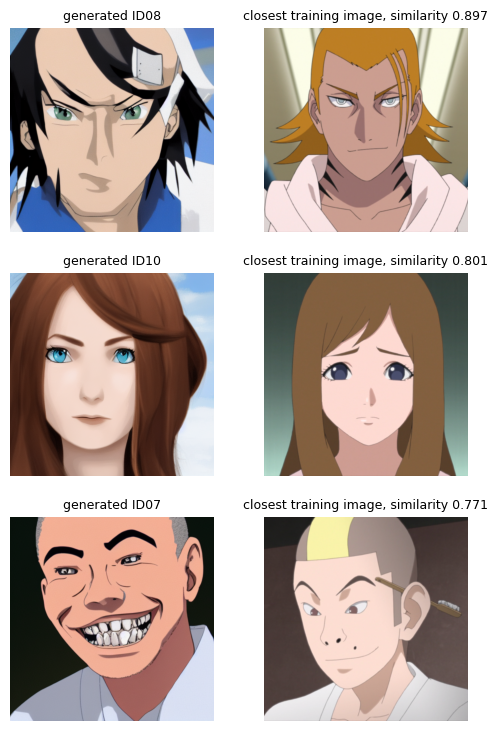

In [19]:
mem = evaluate.memorization(clip, FINAL_RUN, prompts)
mem.to_csv(common.METRICS / "memorization.csv", index=False)
display(mem)

fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for row, (_, r) in enumerate(mem.head(3).iterrows()):
    axes[row, 0].imshow(Image.open(common.image_path(FINAL_RUN, r["prompt_id"], 0)))
    axes[row, 0].set_title(f"generated {r['prompt_id']}", fontsize=9)
    axes[row, 1].imshow(Image.open(common.DATA / "train" / r["closest_train_image"]))
    axes[row, 1].set_title(f"closest training image, similarity {r['similarity']:.3f}", fontsize=9)
    for ax in axes[row]: ax.axis("off")
fig.savefig(common.OUTPUTS / "memorization_top3.jpg", dpi=80, bbox_inches="tight")
plt.show()

### Failure modes
The final run's lowest CLIP-score images (where it ignored the prompt), to pick two failure
modes for the report.

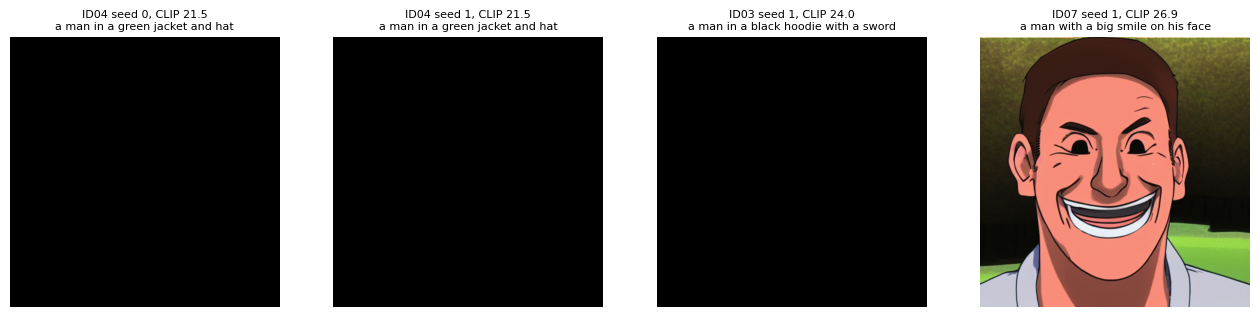

In [20]:
worst = clip_df[clip_df.model == FINAL_RUN].nsmallest(4, "clip_score")
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
text = {p["prompt_id"]: p["prompt"] for p in prompts}
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(common.image_path(FINAL_RUN, r["prompt_id"], r["seed"])))
    ax.set_title(f"{r['prompt_id']} seed {r['seed']}, CLIP {r['clip_score']:.1f}\n{text[r['prompt_id']][:45]}", fontsize=8)
    ax.axis("off")
fig.savefig(common.OUTPUTS / "failure_examples.jpg", dpi=80, bbox_inches="tight")
plt.show()

### Human evaluation
25 blinded pairs, final run vs base model. Raters look at `outputs/human_eval/pair_XX.jpg` (in `MyDrive/data266_p2`),
copy `ratings_TEMPLATE.csv` to `metrics/human_eval/ratings_<name>.csv` and write A or B in both columns.
Once the three files are there, run this notebook again (finished training is skipped).

In [21]:
from part2_diffusion.src import human_eval
human_eval.make_pairs(FINAL_RUN)
result = human_eval.score(FINAL_RUN)
if result is not None:
    win_rates, per_rater = result
    display(win_rates.round(3)); display(per_rater.round(3))

,final_run_win_rate,all_raters_agree
question,,
better_naruto_style,0.827,0.72
better_prompt_match,0.293,0.36


question,better_naruto_style,better_prompt_match
rater,,
punit_chittora,0.84,0.48
shreya,0.80,0.20
zoheb,0.84,0.20


## Results

In [22]:
table = metrics.copy()
table["gpu_hours"] = [stats[m]["gpu_hours"] if m in stats else None for m in table.index]
table["peak_gpu_memory_gb"] = [stats[m]["peak_gpu_memory_gb"] if m in stats else None for m in table.index]
if result is not None:
    table.loc[FINAL_RUN, "human_win_rate_style"] = win_rates.loc["better_naruto_style", "final_run_win_rate"]
    table.loc[FINAL_RUN, "human_win_rate_prompt"] = win_rates.loc["better_prompt_match", "final_run_win_rate"]
table.to_csv(common.METRICS / "results_table.csv")
table.round(4)

,kid_mean,kid_std,clip_score,clip_in_domain,lpips_between_seeds,gpu_hours,peak_gpu_memory_gb,human_win_rate_style,human_win_rate_prompt
base,0.1243,0.0181,31.8782,30.4415,0.8061,NaN,NaN,NaN,NaN
run1_lora_r4,0.0532,0.0247,29.8986,28.3327,0.7622,0.705,3.54,0.8267,0.2933
run2_lora_r32,0.0761,0.0478,29.3289,27.3170,0.7222,0.716,3.60,NaN,NaN
